In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random
from data_pipeline import get_data, get_breads_names
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import BitsAndBytesConfig
import transformers
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import ViTForImageClassification, get_cosine_schedule_with_warmup
transformers.logging.set_verbosity_error()      # hides warnings and the load report
transformers.logging.disable_progress_bar()
import optuna
from optuna.study import MaxTrialsCallback
from optuna.trial import TrialState
from optuna.visualization import (plot_optimization_history, plot_param_importances, plot_intermediate_values, plot_slice)
import plotly
optuna.logging.set_verbosity(optuna.logging.WARNING)
from torch.optim import AdamW
from tqdm.auto import tqdm
import time
import os
import gc, sys

from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training, PeftModel

cuda = "cuda" if torch.cuda.is_available() else "cpu"
RANDOM_STATE = 42
print(cuda)

W1110 17:41:46.413000 18660 site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


cuda


In [2]:
def set_seed(seed=RANDOM_STATE):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(RANDOM_STATE)

In [3]:
train_loader, val_loader, test_loader = get_data(batch_size=32)
breads_names = get_breads_names()

In [4]:
MODEL_NAME = "google/vit-base-patch16-224-in21k"
id2label = {i:name for i, name in enumerate(breads_names)}
label2id = {name:i for i, name in enumerate(breads_names)}

In [5]:
def clear_gpu(verbose=True):
    g = globals()

    # 1. Delete global variables holding models, optimizers, schedulers or GPU tensors
    removed = []
    for name, obj in list(g.items()):
        if name.startswith("_"):
            continue
        if (isinstance(obj, (nn.Module, torch.optim.Optimizer, torch.optim.lr_scheduler.LRScheduler))
                or (torch.is_tensor(obj) and obj.is_cuda)):
            del g[name]
            removed.append(name)

    # 2. Clear hidden references: crashed-cell tracebacks and notebook output history
    sys.last_traceback = sys.last_value = sys.last_type = None
    try:
        get_ipython().run_line_magic("reset", "-f out")
    except NameError:
        pass   # not running in a notebook

    # 3. Free the memory and hand it back to the driver
    gc.collect()
    torch.cuda.empty_cache()

    allocated = torch.cuda.memory_allocated() / 1e9
    reserved = torch.cuda.memory_reserved() / 1e9
    if verbose:
        print("Removed:", removed or "nothing")
        print(f"Allocated: {allocated:.3f} GB | Reserved: {reserved:.3f} GB")
    return allocated

# Hyper Parameter Tuning

## ViT-Base Full Training

In [6]:
def evaluate(model, loader):
    model.eval()
    correct = total = 0
    loss_sum = 0.0
    with torch.no_grad():
        for images, labels, _, _ in loader:
            images, labels = images.to(cuda), labels.to(cuda)
            out = model(pixel_values=images, labels=labels)
            loss_sum += out.loss.item() * len(labels)
            correct += (out.logits.argmax(1) == labels).sum().item()
            total += len(labels)
    return loss_sum / total, correct / total      

In [7]:
def fully_train_model(model,train_loader, val_loader, **kwargs):
    lr = kwargs["lr"]
    #batch_size = kwargs["batch_size"]
    weight_decay = kwargs["weight_decay"]
    epochs = kwargs["epochs"]
    
    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    steps = epochs * len(train_loader)
    schedular = get_cosine_schedule_with_warmup(optimizer, int(0.1 * steps), steps)

    trainable_params_num = sum(p.numel() for p in model.parameters() if p.requires_grad)

    history = []
    torch.cuda.reset_peak_memory_stats()
    for epoch in range(epochs):
        model.train()
        total_loss_sum = 0
        n = 0
        pbar = tqdm(train_loader, desc=f"Epoch: {epoch}", leave=False)

        torch.cuda.synchronize()
        start = time.perf_counter()
        for images, labels, _, _ in pbar:
            images = images.to(cuda)
            labels = labels.to(cuda)
            loss = model(pixel_values = images, labels= labels).loss
            
            total_loss_sum += loss.item() * len(labels)
            n += len(labels)
            loss.backward()
            optimizer.step()
            schedular.step()
            optimizer.zero_grad()
            pbar.set_postfix(loss=f"{total_loss_sum / n:.4f}")

        torch.cuda.synchronize()
        train_time = time.perf_counter() - start

        train_loss = total_loss_sum / n
        val_loss, val_acc = evaluate(model, val_loader)

        history.append({
            "epoch" : epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "train_time_s" : train_time,
            "images_per_s" : n / train_time,
            "peak_mem_allocated_gb" : torch.cuda.max_memory_allocated() / 1e9,
            "peak_mem_reserved_gb" : torch.cuda.max_memory_reserved() / 1e9,
            "trainable_params" : trainable_params_num
        })

        h = history[-1]
        print(f"Epoch {epoch} | train_loss {h['train_loss']:.4f} | val_loss {val_loss:.4f} | "
              f"val_acc {val_acc:.4f} | {train_time:.1f}s | peak {h['peak_mem_allocated_gb']:.2f} GB")
        
    return model, pd.DataFrame(history)

In [8]:
SEARCH_EPOCHS = 3

def objective(trial):
    set_seed(RANDOM_STATE)
    lr = trial.suggest_float("lr", 1e-5, 5e-4, log=True)
    
    #weight_decay = trial.suggest_float("weight_decay", 0.0, 0.1)
    weight_decay = 0.05

    #label_smoothing = trial.suggest_float("label_smoothing", 0.0, 0.2)
    label_smoothing = 0
    
    model = ViTForImageClassification.from_pretrained(
        MODEL_NAME, num_labels=len(id2label), 
        id2label=id2label, 
        label2id=label2id,
        ).to(cuda)

    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    steps = SEARCH_EPOCHS * len(train_loader)

    scheduler = get_cosine_schedule_with_warmup(optimizer, int(0.1 * steps), steps)
    
    history = []
    try:
        for epoch in range(SEARCH_EPOCHS):
            model.train()
            epoch_loss_sum = 0
            n = 0
            pbar = tqdm(train_loader, desc=f"Trial {trial.number} | epoch {epoch}", leave=False)
            for images, labels, _, _ in pbar:
                logits = model(pixel_values=images.to(cuda)).logits
                loss = F.cross_entropy(logits, labels.to(cuda), label_smoothing=label_smoothing)
                epoch_loss_sum += loss.item() * len(labels)
                n += len(labels)
                loss.backward()
                optimizer.step()
                scheduler.step()
                optimizer.zero_grad()
                pbar.set_postfix(loss=f"{epoch_loss_sum / n:.4f}")

            train_loss = epoch_loss_sum / n
            val_loss, val_acc = evaluate(model, val_loader)

            history.append({
                "epoch" : epoch+1,
                "train_loss" : train_loss,
                "val_loss": val_loss,
                "val_accuracy": val_acc
            })

            trial.set_user_attr("history", history)
            trial.report(val_loss, epoch)

            print(f"Trial {trial.number} | epoch {epoch} | train_loss {train_loss:.4f} | "
                  f"val_loss {val_loss:.4f} | val_acc {val_acc:.4f}")
            
            if trial.should_prune():
                raise optuna.TrialPruned()
        return val_loss
    finally:
        del model, optimizer
        gc.collect()
        torch.cuda.empty_cache()        

In [9]:
# optuna.delete_study(study_name="vitb_full_loss_lr_only", storage="sqlite:///optuna.db")
# optuna.delete_study(study_name="vitb_qlora_lr_only", storage="sqlite:///optuna.db")

In [10]:
study_full = optuna.create_study(
    study_name="vitb_full_loss_lr_only",  
    storage="sqlite:///optuna.db",
    load_if_exists=True,
    direction='minimize',
    sampler=optuna.samplers.TPESampler(n_startup_trials=5, seed=RANDOM_STATE),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=3),
)

#study_full.optimize(objective, n_trials=10, callbacks=[MaxTrialsCallback(10, states=(TrialState.COMPLETE, TrialState.PRUNED))])
print(study_full.best_params)

{'lr': 0.00044520563259437245}


In [11]:
plot_optimization_history(study_full).show()   # best validation loss improving over trials
plot_param_importances(study_full).show()      # which hyperparameter mattered most
plot_intermediate_values(study_full).show()         # learning curve per trial, pruned ones cut short
plot_slice(study_full).show()                  # loss vs each hyperparameter's value

In [12]:
BEST_VIT_BASE_FULL_LR = study_full.trials_dataframe().sort_values(by=['value'], ascending=True).iloc[0]['params_lr']

BEST_VIT_BASE_FULL_LR

np.float64(0.00044520563259437245)

In [13]:
path = f"trained_models/vitb_full_seed{RANDOM_STATE}"

if os.path.exists(os.path.join(path, "history.csv")):
    # full_model = ViTForImageClassification.from_pretrained(path).to(cuda)
    full_training_history = pd.read_csv(os.path.join(path, "history.csv"))
else:
    clear_gpu()
    set_seed(RANDOM_STATE)
    full_model = ViTForImageClassification.from_pretrained(
        MODEL_NAME,
        num_labels=len(id2label),
        id2label=id2label,
        label2id=label2id
    ).to(cuda)

    full_model, full_training_history = fully_train_model(
        model=full_model,
        train_loader=train_loader,
        val_loader=val_loader,
        lr=BEST_VIT_BASE_FULL_LR,
        weight_decay=0.05,
        epochs=10
    )

    full_model.save_pretrained(path)
    full_training_history["lr"] = BEST_VIT_BASE_FULL_LR
    full_training_history["weight_decay"] = 0.05
    full_training_history.to_csv(os.path.join(path, "history.csv"), index=False)

In [14]:
def plot_training_history(history, title="Training history", save_path=None):
    """Plot loss, validation accuracy, time per epoch and peak memory from a history DataFrame."""
    h = history
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    ax = axes[0, 0]
    ax.plot(h["epoch"], h["train_loss"], marker="o", label="train loss")
    ax.plot(h["epoch"], h["val_loss"], marker="o", label="validation loss")
    ax.set_title("Loss"); ax.set_ylabel("cross-entropy loss"); ax.legend()

    ax = axes[0, 1]
    ax.plot(h["epoch"], h["val_accuracy"] * 100, marker="o", color="tab:green")
    ax.set_title("Validation accuracy"); ax.set_ylabel("accuracy (%)")

    ax = axes[1, 0]
    ax.bar(h["epoch"], h["train_time_s"], color="tab:orange")
    ax.set_title("Training time per epoch"); ax.set_ylabel("seconds")

    ax = axes[1, 1]
    ax.plot(h["epoch"], h["peak_mem_allocated_gb"], marker="o", label="peak allocated")
    ax.plot(h["epoch"], h["peak_mem_reserved_gb"], marker="o", label="peak reserved")
    ax.set_title("Peak GPU memory"); ax.set_ylabel("GB"); ax.legend()

    for ax in axes.flat:
        ax.set_xlabel("epoch")
        ax.set_xticks(h["epoch"])
        ax.grid(alpha=0.3)

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()

    # Summary (epoch 0's time is skipped: it includes one-time setup)
    later = h.iloc[1:] if len(h) > 1 else h
    summary = {
        "final_val_accuracy": h["val_accuracy"].iloc[-1],
        "final_val_loss": h["val_loss"].iloc[-1],
        "avg_time_per_epoch_s": later["train_time_s"].mean(),
        "avg_images_per_s": later["images_per_s"].mean(),
        "peak_mem_allocated_gb": h["peak_mem_allocated_gb"].max(),
    }
    for k, v in summary.items():
        print(f"{k:24s} {v:.4f}")
    return summary

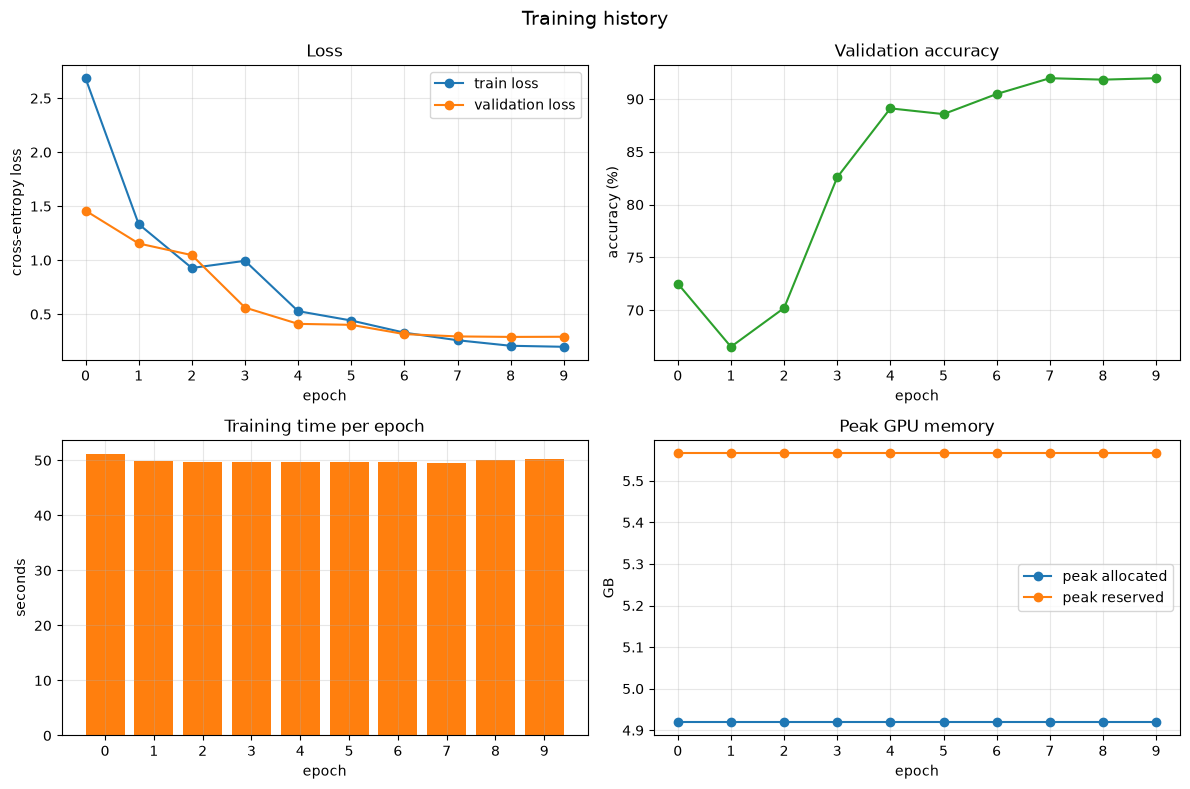

final_val_accuracy       0.9197
final_val_loss           0.2908
avg_time_per_epoch_s     49.8032
avg_images_per_s         59.1340
peak_mem_allocated_gb    4.9197


In [15]:
_ = plot_training_history(full_training_history)

## ViT-Base QLoRA Training

In [16]:
def build_qlora_model():
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=torch.bfloat16,
        llm_int8_skip_modules=["classifier"],
    )

    model = ViTForImageClassification.from_pretrained(
        MODEL_NAME, num_labels=len(id2label), id2label=id2label, label2id=label2id,
        quantization_config=bnb_config, device_map={"": 0},
    )

    model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=False)
    lora_config = LoraConfig(
        r=16, lora_alpha=16, lora_dropout=0,
        target_modules= "all-linear",
        modules_to_save=["classifier"]
    )

    return get_peft_model(model, lora_config)

In [17]:
def objective_qlora(trial):
    set_seed(seed=RANDOM_STATE)
    lr = trial.suggest_float("lr", 1e-4, 5e-3, log=True)

    torch.cuda.reset_peak_memory_stats()
    model = build_qlora_model()
    trainable = [p for p in model.parameters() if p.requires_grad]
    optimizer = AdamW(trainable, lr=lr, weight_decay=0.05)
    steps = SEARCH_EPOCHS * len(train_loader)
    scheduler = get_cosine_schedule_with_warmup(optimizer, int(0.1 * steps), steps)

    history = []
    try:
        for epoch in range(SEARCH_EPOCHS):
            model.train()
            loss_sum, n = 0.0, 0
            pbar = tqdm(train_loader, desc=f"Trial {trial.number} | epoch {epoch}", leave=False)
            for images, labels, _, _ in pbar:
                loss = model(pixel_values=images.to(cuda), labels=labels.to(cuda)).loss
                loss.backward()
                optimizer.step(); scheduler.step(); optimizer.zero_grad()
                loss_sum += loss.item() * len(labels)
                n += len(labels)
                pbar.set_postfix(loss=f"{loss_sum / n:.4f}")

            train_loss = loss_sum / n
            val_loss, val_acc = evaluate(model, val_loader)
            history.append({"epoch": epoch, "train_loss": loss_sum / n,
                            "val_loss": val_loss, "val_accuracy": val_acc})
            trial.set_user_attr("history", history)
            trial.set_user_attr("peak_memory_gb", torch.cuda.max_memory_allocated() / 1e9)

            trial.report(val_loss, epoch)
            print(f"Trial {trial.number} | epoch {epoch+1} | train_loss {train_loss:.4f} | "
                              f"val_loss {val_loss:.4f} | val_acc {val_acc:.4f}")
            
            if trial.should_prune():
                raise optuna.TrialPruned()
        return val_loss
    finally:
        del model, optimizer
        gc.collect()
        torch.cuda.empty_cache()

In [18]:
study_qlora = optuna.create_study(
    study_name="vitb_qlora_lr_only",
    storage="sqlite:///optuna.db",
    load_if_exists=True,
    direction="minimize",
    sampler=optuna.samplers.TPESampler(n_startup_trials=5, seed=RANDOM_STATE),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=3),
)
# study_qlora.optimize(
#     objective_qlora, 
#     n_trials=15,     
#     callbacks=[MaxTrialsCallback(10, states=(TrialState.COMPLETE, TrialState.PRUNED))],
# )
print(study_qlora.best_params)

{'lr': 0.0017524101118128151}


In [19]:
plot_optimization_history(study_qlora).show()   # best validation loss improving over trials
plot_param_importances(study_qlora).show()      # which hyperparameter mattered most
plot_intermediate_values(study_qlora).show()         # learning curve per trial, pruned ones cut short
plot_slice(study_qlora).show()                  # loss vs each hyperparameter's value

In [20]:
BEST_VIT_BASE_QLORA_LR = study_qlora.trials_dataframe().sort_values(by=['value'], ascending=True).loc[0]['params_lr']

In [21]:
BEST_VIT_BASE_QLORA_LR, BEST_VIT_BASE_FULL_LR

(np.float64(0.00043284502212938834), np.float64(0.00044520563259437245))

In [22]:
path = f"trained_models/vitb_qlora_seed{RANDOM_STATE}"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
    llm_int8_skip_modules=["classifier"],
)

if os.path.exists(os.path.join(path, "history.csv")):
    base = ViTForImageClassification.from_pretrained(
        MODEL_NAME, num_labels=len(id2label), id2label=id2label, label2id=label2id,
        quantization_config=bnb_config, device_map={"": 0},
    )
    qlora_model = PeftModel.from_pretrained(base, path)
    qlora_training_history = pd.read_csv(os.path.join(path, "history.csv"))
else:
    set_seed(RANDOM_STATE)
    clear_gpu()
    qlora_model = build_qlora_model().to(cuda)

    qlora_model, qlora_training_history = fully_train_model(
        model=qlora_model,
        train_loader=train_loader,
        val_loader=val_loader,
        lr=BEST_VIT_BASE_QLORA_LR,
        weight_decay=0.05,
        epochs=10,
    )

    qlora_model.save_pretrained(path)
    qlora_training_history["lr"] = BEST_VIT_BASE_QLORA_LR
    qlora_training_history["weight_decay"] = 0.05
    qlora_training_history.to_csv(os.path.join(path, "history.csv"), index=False)

Flushing output cache (2 entries)
Removed: nothing
Allocated: 0.000 GB | Reserved: 0.000 GB


Epoch: 0:   0%|          | 0/93 [00:00<?, ?it/s]

Epoch 0 | train_loss 3.2661 | val_loss 2.2394 | val_acc 0.8476 | 37.9s | peak 4.03 GB


Epoch: 1:   0%|          | 0/93 [00:00<?, ?it/s]

Epoch 1 | train_loss 1.3873 | val_loss 0.6741 | val_acc 0.9061 | 37.3s | peak 4.03 GB


Epoch: 2:   0%|          | 0/93 [00:00<?, ?it/s]

... (11 outputs left out)

Epoch: 8:   0%|          | 0/93 [00:00<?, ?it/s]

Epoch 8 | train_loss 0.2243 | val_loss 0.1808 | val_acc 0.9605 | 37.2s | peak 4.03 GB


Epoch: 9:   0%|          | 0/93 [00:00<?, ?it/s]

Epoch 9 | train_loss 0.2411 | val_loss 0.1796 | val_acc 0.9605 | 37.2s | peak 4.03 GB


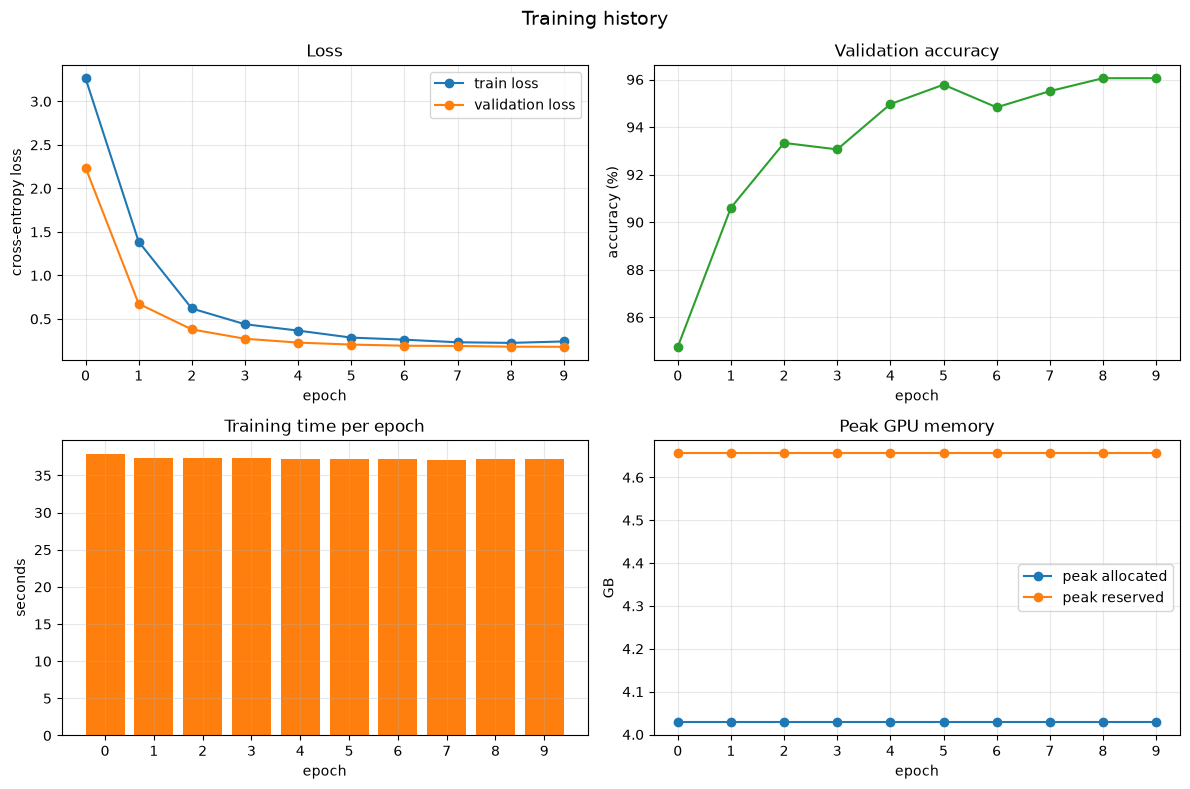

final_val_accuracy       0.9605
final_val_loss           0.1796
avg_time_per_epoch_s     37.2169
avg_images_per_s         79.1311
peak_mem_allocated_gb    4.0290


{'final_val_accuracy': np.float64(0.9605442176870749),
 'final_val_loss': np.float64(0.17961538288058068),
 'avg_time_per_epoch_s': np.float64(37.21686931111107),
 'avg_images_per_s': np.float64(79.13109719278549),
 'peak_mem_allocated_gb': np.float64(4.02903552)}

In [23]:
plot_training_history(qlora_training_history)